In [35]:
import pandas as pd

In [36]:
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'
df = pd.read_csv(url)
df.head(2)

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3


In [37]:
df = df.fillna(0)
df.isnull().sum()

model_year             0
origin                 0
fuel_type              0
drivetrain             0
num_doors              0
engine_displacement    0
num_cylinders          0
horsepower             0
vehicle_weight         0
acceleration           0
fuel_efficiency_mpg    0
dtype: int64

In [38]:
from sklearn.model_selection import train_test_split

In [39]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [40]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

Question 1

In [41]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.tree import DecisionTreeRegressor, export_text

dv = DictVectorizer(sparse=True)

dicts_train = df_train.to_dict(orient='records')
dicts_val = df_val.to_dict(orient='records')

X_train = dv.fit_transform(dicts_train)
X_val = dv.transform(dicts_val)
dt = DecisionTreeRegressor(max_depth=1)
dt.fit(X_train, y_train)

y_pred = dt.predict(X_val)
print(export_text(dt, feature_names=dv.get_feature_names_out()))
# answer - model_year


|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]



Question 2

In [42]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import root_mean_squared_error

rf = RandomForestRegressor(n_estimators=10, random_state=1,n_jobs=-1)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_val)
rmse = root_mean_squared_error(y_val, y_pred)
print(rmse)
# answer = 1.837



1.8332197358745623


Question 3

In [43]:
estimators = [10,50,100,150]
scores = {}
for n in estimators:
    rf = RandomForestRegressor(n_estimators=n, random_state=1,n_jobs=-1)
    rf.fit(X_train, y_train)
    y_pred = rf.predict(X_val)
    rmse = root_mean_squared_error(y_val, y_pred)
    scores[n] = round(rmse,3)
print(scores)
#answer - 150

{10: 1.833, 50: 1.774, 100: 1.77, 150: 1.769}


Question 4

In [44]:
import numpy as np
depths = [10,15,20,25]
results = {}
for d in depths:
    scores = []
    for n in estimators:
        rf = RandomForestRegressor(n_estimators=n, random_state=1,n_jobs=-1, max_depth=d)
        rf.fit(X_train, y_train)
        y_pred = rf.predict(X_val)
        rmse = root_mean_squared_error(y_val, y_pred)
        scores.append(rmse)
    results[d] = np.mean(scores)
print(results)
# asnwer - 10

{10: np.float64(1.7543924943801008), 15: np.float64(1.7842243445385957), 20: np.float64(1.7867711878395158), 25: np.float64(1.7863054936840876)}


Question 5

In [45]:
rf = RandomForestRegressor(n_estimators=10, random_state=1,n_jobs=-1, max_depth=20)
rf.fit(X_train, y_train)
importances = pd.Series(
rf.feature_importances_,
index=dv.get_feature_names_out(),
name='importance'
)
importances.sort_values(ascending=False)
# vehicle_weight

model_year                      0.296107
vehicle_weight                  0.203313
fuel_type=Gasoline              0.160712
horsepower                      0.078271
engine_displacement             0.061281
acceleration                    0.054998
origin=USA                      0.042152
drivetrain=Front-wheel drive    0.020062
num_doors                       0.019401
fuel_type=Diesel                0.016571
fuel_type=Hybrid                0.016272
drivetrain=All-wheel drive      0.007951
num_cylinders                   0.007318
origin=Asia                     0.006515
drivetrain=Rear-wheel drive     0.005638
origin=Europe                   0.003436
Name: importance, dtype: float64

Question 6

In [46]:
import xgboost as xgb

In [47]:
feature_names = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=feature_names)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=feature_names)

watchlist = [(dtrain, 'train'), (dval, 'val')]
scores = {}
for eta in [0.3, 0.1]:
    evals_result ={}
    xgb_params = {
        'eta': eta, 
        'max_depth': 6,
        'min_child_weight': 1,
        
        'objective': 'reg:squarederror',
        'nthread': 8,
        
        'seed': 1,
        'verbosity': 1,
    }

    model = xgb.train(xgb_params, dtrain, num_boost_round=100, evals=watchlist, verbose_eval=0, evals_result=evals_result)
    columns = ['iter', 'train_auc', 'val_auc']
    train_aucs = list(evals_result['train'].values())[0]
    val_aucs = list(evals_result['val'].values())[0]

    df_results = pd.DataFrame(
        list(zip(range(1, len(train_aucs) + 1), train_aucs, val_aucs)),
        columns=columns
    )

    key = f'eta={eta}'
    scores[key] = df_results




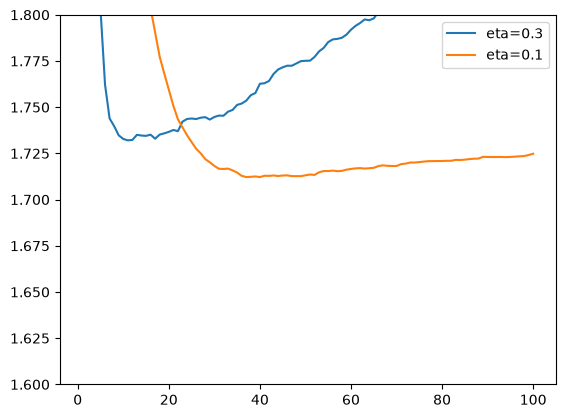

In [48]:
import matplotlib.pyplot as plt
%matplotlib inline

for key, df_score in scores.items():
    plt.plot(df_score.iter, df_score.val_auc, label=key)

plt.ylim(1.6, 1.8)
plt.legend()